In [ ]:
import Dependency.Data_splitting as spl
from Dependency.one_hot_encoding import one_hot_encoding
import pandas
from Models import Random_Forest,SVM,Hist_Gradient_Boosting,Categorical_NB
from sklearn.decomposition import PCA

#selecting training and testing data from cleaned dataset
dataset = spl.selecting()

#one-hot encoding
encoded = one_hot_encoding(dataset["training_data"], dataset["testing_data"])
dataset["training_data_X"] = encoded["training"]
dataset["testing_data_X"] = encoded["testing"]

#splitting target variable from everything else
dataset = spl.targeting(dataset)

if(True):
    #normalization of data for pca
    dataset["training_data_X"] = spl.normalization(dataset["training_data_X"])
    dataset["testing_data_X"] = spl.normalization(dataset["testing_data_X"])

    #PCA
    pca = PCA(n_components=0.99)
    dataset["training_data_X"] = pandas.DataFrame(pca.fit_transform(dataset["training_data_X"]))
    dataset["testing_data_X"] = pandas.DataFrame(pca.transform(dataset["testing_data_X"]))

result = []

In [4]:
#Categorical Naive Bayes
if(True):
    result.append(Categorical_NB.Categorical_Naive_Bayes(dataset))

In [5]:
#Random Forest
if(True):
    result.append(Random_Forest.Forest(dataset))

In [6]:
#Hist_Grabient_Boosting
if(True):
    result.append(Hist_Gradient_Boosting.H_Grad_Boosting(dataset, True))

In [7]:
#SVM (SVC)
if(True):
    result.append(SVM.SVM_svc(dataset))

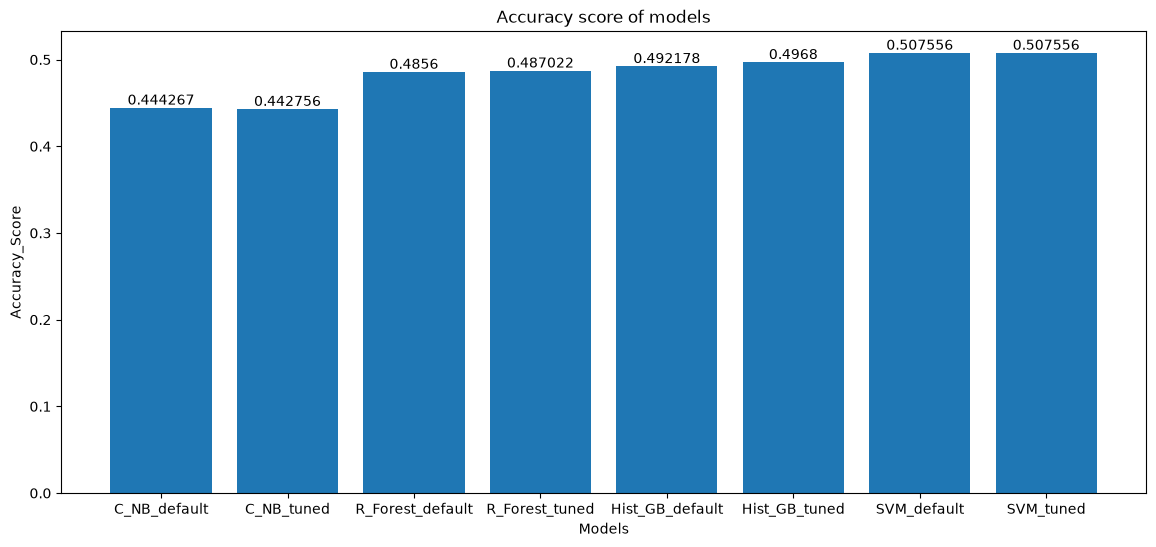

In [8]:
import matplotlib.pyplot as plt

models = []
accuracy = []
f1 = []
for res in result:
    for val in res:
        models.append(val[0])
        accuracy.append(val[1])
        f1.append(val[2])

f, plot = plt.subplots()
f.set_figwidth(14)
f.set_figheight(6)

p = plot.bar(models, accuracy)

plot.bar_label(p)

plt.title('Accuracy score of models')
plt.xlabel('Models')
plt.ylabel('Accuracy_Score')
plt.show()

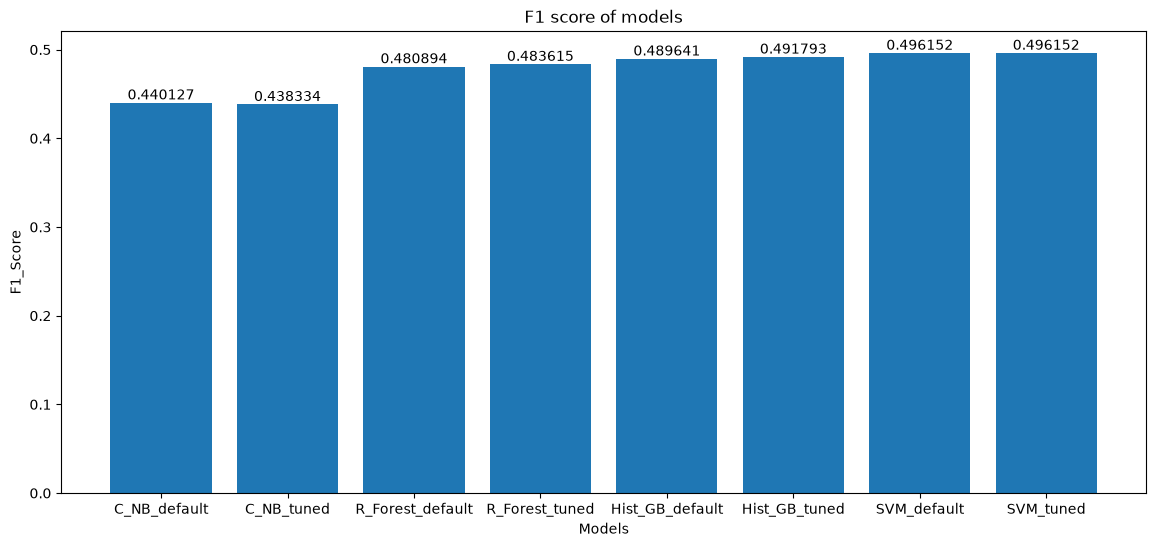

In [9]:
f, plot = plt.subplots()
f.set_figwidth(14)
f.set_figheight(6)

p = plot.bar(models, f1)

plot.bar_label(p)

plt.title('F1 score of models')
plt.xlabel('Models')
plt.ylabel('F1_Score')
plt.show()